In [1]:
# Loading libraries

import astropy
import os
import numpy as np
import pandas as pd
import matplotlib
import scipy
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.table import Table
from matplotlib import pyplot as plt


In [2]:
alma_regions = Table.read("../alma_input/almaprops_2024_all_20250219.tab", format="ascii.ipac")
print(alma_regions[:2])
print("\n\n\n")

    ALMAGAL_ID           ORIG_ID        INTERNAL_ID ... FIT_FLAG OBS_SAMPLE
                                                    ...                    
----------------- --------------------- ----------- ... -------- ----------
AG010.1313-0.7687 HIGALBM10.1330-0.7710       46677 ...        -       near
AG010.1392-0.7831 HIGALBM10.1395-0.7833       46696 ...        -       near






In [3]:
spitzer_clumps = Table.read("../output/spitzer_clumps.tbl", format="ascii.ipac")
print(spitzer_clumps[:2])
print("\n\n\n")

cntr_01  dist_x    pang_x   internal_id_01 ... color45_58 color45_80 color58_80
         arcsec     deg                    ...                                 
------- -------- ---------- -------------- ... ---------- ---------- ----------
      1 2.867081 -55.508188          46677 ...      0.471      0.367     -0.104
      1 4.406157  86.064855          46677 ...         --         --         --






In [4]:
alma_clumps = pd.read_csv('../alma_input/7MTM2TM1_Core_catalogue_out_official_v3_run6Apr23+16Jan24_sn-5_may24_clump_cat.txt', comment='\\', skiprows=[2], delimiter='\s+')
print(alma_clumps[6001:6004])
print("\n\n\n")

      ID               CLUMP          X          Y         RA        DEC  \
6001  22  G323.7399-00.2617B  386.92831  335.97809  232.93886 -56.514006   
6002  23  G323.7399-00.2617B  374.90641  340.99945  232.93932 -56.513900   
6003  20  G323.7399-00.2617B  355.04385  326.97879  232.94008 -56.514196   

           GLON      GLAT     F_PEAK         S/N  ...  Back_onpeak_jybm  \
6001  323.73984 -0.262544  1489.3764   31.570764  ...          0.004688   
6002  323.74011 -0.262602  6066.5668  128.594859  ...          0.006919   
6003  323.74028 -0.263085  1283.1450   27.199214  ...          0.011580   

            Rcore  Surfd_core        n(H2)              AG_ID  \
6001   984.988790    3.902623   63200000.0  AG323.7408-0.2633   
6002  1044.259595   15.896265  243000000.0  AG323.7408-0.2633   
6003   973.958180    3.362233   55100000.0  AG323.7408-0.2633   

                 ORIG_ID  RADIO_INFO  RADIO_MATCH  Surfd_nd VLSR_clump  
6001  G323.7399-00.2617B           1            0      1.58 

In [14]:
match_table = Table(
    names=['alma_clump','spitzer_clump','alma_ra','alma_dec','spitzer_ra','spitzer_dec','separation_arcsec'],
    dtype=['str','str','float64','float64','float64','float64','float64']
)

count = 0

test_regions = 100

for region in alma_regions[:test_regions]: # Just for the first 100 regions

    count +=1
    spitzer_clumps_cut = spitzer_clumps[spitzer_clumps["internal_id_01"] == str(region["INTERNAL_ID"])]
    alma_clumps_cut = alma_clumps[alma_clumps["CLUMP"] == str(region["INTERNAL_ID"])].reset_index(drop=True)

    for alma_index in range(len(alma_clumps_cut)):
        clump_coords = SkyCoord(alma_clumps_cut["RA"][alma_index], alma_clumps_cut["DEC"][alma_index], unit=(u.deg, u.deg), frame="icrs")

        radius = 1*u.arcsec

        for spitzer_clump in spitzer_clumps_cut:
            spitzer_coords = SkyCoord(spitzer_clump["ra"], spitzer_clump["dec"], unit=(u.deg, u.deg), frame="icrs")

            if clump_coords.separation(spitzer_coords) < radius:
            
                match_table.add_row([alma_clumps_cut["CLUMP"][alma_index], spitzer_clump["designation"], 
                                     clump_coords.ra.deg, clump_coords.dec.deg,spitzer_clump["ra"], spitzer_clump["dec"],clump_coords.separation(spitzer_coords)])
                
        print(f"progress: {count}/{len(alma_clumps[:test_regions])}", end="\r")

print('done!')

/home/alex-jurado/anaconda3/lib/python3.13/site-packages/astropy/table/table.py:3195: UserWarning: Units from inserted quantities will be ignored.
  self.insert_row(len(self), vals, mask)


done!ess: 100/100


In [ ]:
match_table['separation_arcsec'].format = "{:.2E}"

print(match_table)

match_table.write("../output/match_table.tbl", format="ascii.ipac", overwrite=True)

    alma_clump          spitzer_clump       ... spitzer_dec separation_arcsec
----------------- ------------------------- ... ----------- -----------------
            47184 SSTGLMC G010.2278-00.2071 ...  -20.191348          1.71E-04
            47184 SSTGLMC G010.2278-00.2071 ...  -20.191348          2.66E-04
            49005 SSTGLMC G010.6702-00.2214 ...  -19.811121          7.92E-05
G010.8856+00.1221 SSTGLMC G010.8851+00.1224 ...  -19.456672          1.03E-04
            50555 SSTGLMC G011.0844-00.5303 ...  -19.597059          1.19E-04
            51554 SSTGLMC G011.3620+00.8027 ...  -18.709532          6.81E-05
            51554 SSTGLMC G011.3640+00.8014 ...  -18.708429          1.38E-04
            52831 SSTGLMC G011.6987-00.3028 ...  -18.949053          2.17E-04
            53795 SSTGLMC G011.9019-00.1433 ...  -18.694229          2.06E-04
            53795 SSTGLMC G011.9040-00.1411 ...  -18.691359          7.86E-05
              ...                       ... ...         ...     

---

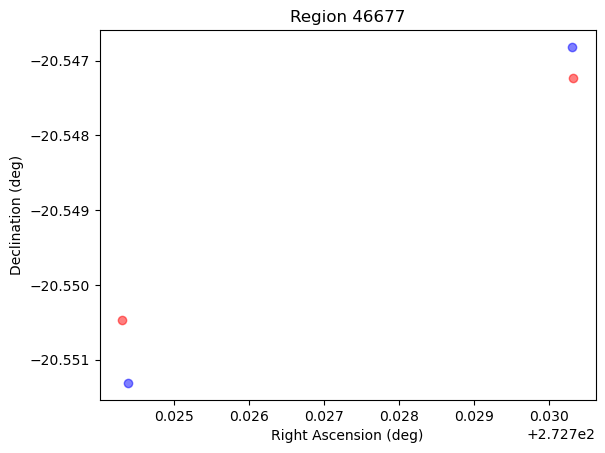

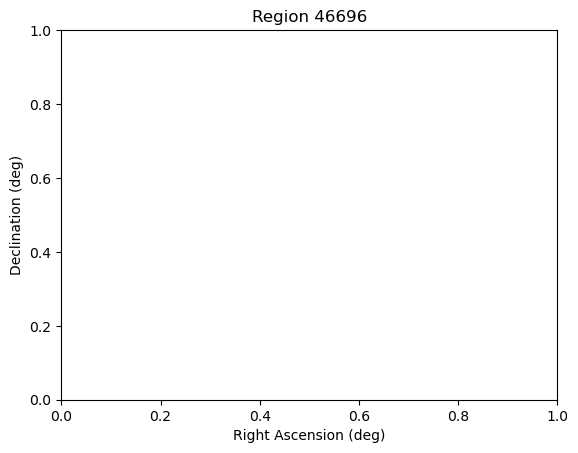

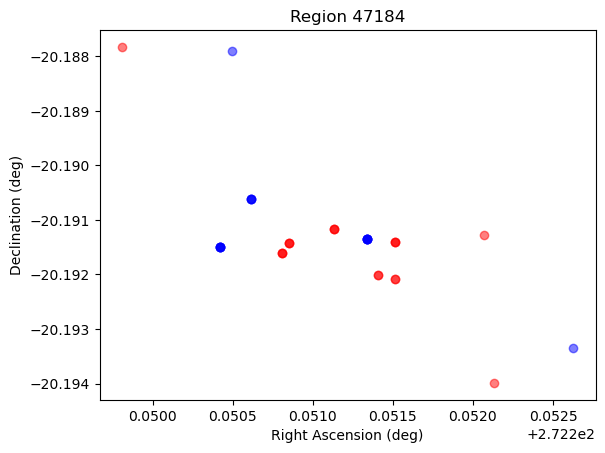

In [15]:
count = 0

test_regions = 3

for region in alma_regions[:test_regions]: # Just for the first 100 regions

    count +=1
    spitzer_clumps_cut = spitzer_clumps[spitzer_clumps["internal_id_01"] == str(region["INTERNAL_ID"])]
    alma_clumps_cut = alma_clumps[alma_clumps["CLUMP"] == str(region["INTERNAL_ID"])].reset_index(drop=True)

    for alma_index in range(len(alma_clumps_cut)):
        clump_coords = SkyCoord(alma_clumps_cut["RA"][alma_index], alma_clumps_cut["DEC"][alma_index], unit=(u.deg, u.deg), frame="icrs")

        radius = 5*u.arcsec

        for spitzer_clump in spitzer_clumps_cut:
            spitzer_coords = SkyCoord(spitzer_clump["ra"], spitzer_clump["dec"], unit=(u.deg, u.deg), frame="icrs")

            if clump_coords.separation(spitzer_coords) < radius:
                
                plt.scatter(spitzer_coords.ra.deg, spitzer_coords.dec.deg, color="blue", label="Spitzer Clump",alpha=0.5)
                plt.scatter(clump_coords.ra.deg, clump_coords.dec.deg, color="red", label="ALMA Clump",alpha=0.5)


    print(f"progress: {count}/{len(alma_clumps[:test_regions])}", end="\r")

    plt.title(f"Region {region['INTERNAL_ID']}")

    g = SkyCoord(region["GLON"], region["GLAT"], unit=(u.deg, u.deg), frame="galactic").icrs

    #plt.ylim(g.dec.deg - 0.01, g.dec.deg + 0.01)
    #plt.xlim(g.ra.deg - 0.01, g.ra.deg + 0.01)
    plt.ylabel("Declination (deg)")
    plt.xlabel("Right Ascension (deg)")    
    plt.show()
    print("\n")
